# Reviewer-response evidence

Run `.venv/bin/python paper_analysis/run_review.py` from the repository first. This notebook presents the same saved calculations; it does not independently select a cohort or change policies. All counts include repeated qualifying ECTP slabs. See `results/reviewer_response_support.md` for suggested response text.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/snowpyt_mechparams").exists())
results = root / "paper_analysis/results"
comparison = json.loads((results / "comparison.json").read_text())
audit = json.loads((results / "corrected/audit_summary.json").read_text())
metadata = json.loads((results / "run_metadata.json").read_text())

## Applicability and changes

Domains are inclusive at nominal density. Schöttner’s intervals are observed calibration boundaries supplied by the author, not accuracy guarantees. The equations still normalize by 917 kg m⁻³; only the boundary conversion uses 916.7.

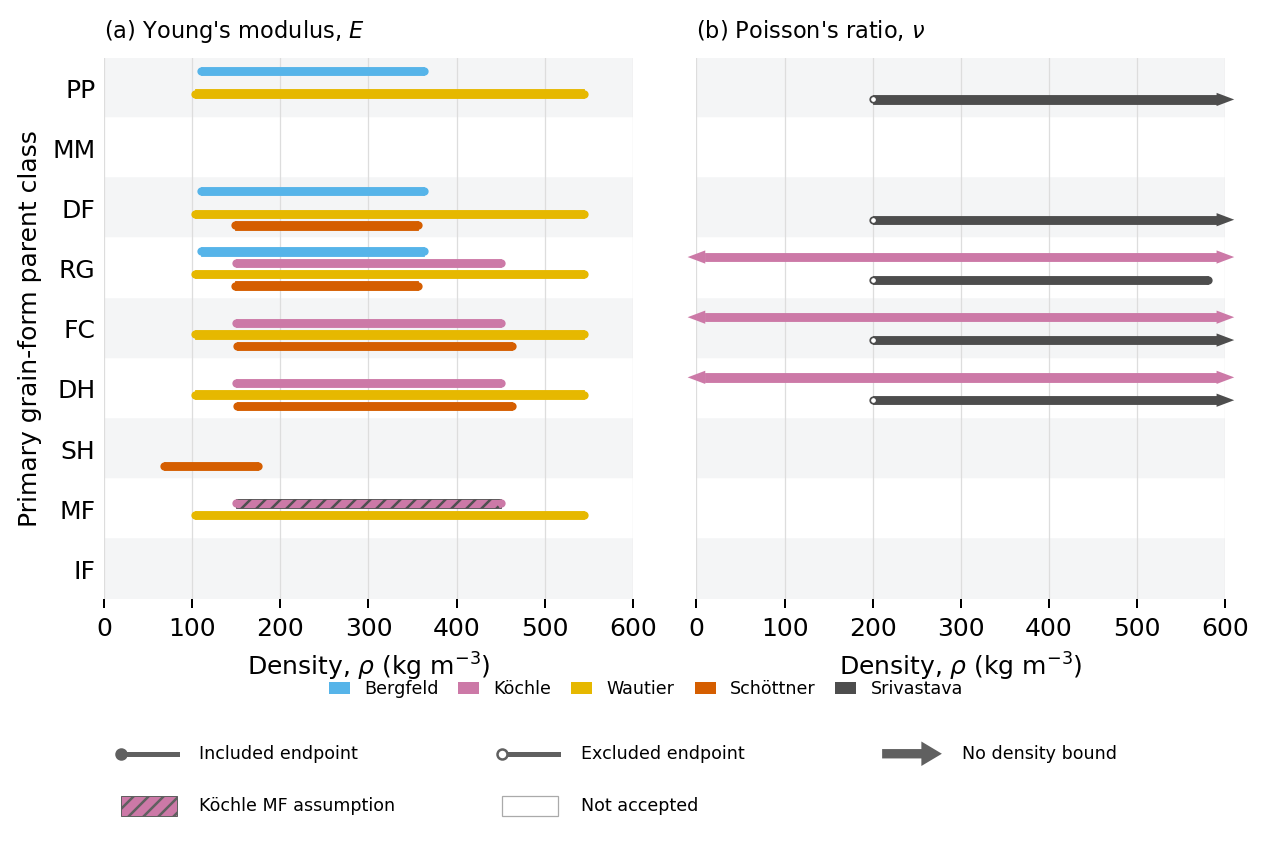

{'attempts_with_changed_success': 362,
 'shared_success_nominal_values_unchanged': True,
 'shared_successes_with_changed_sigma': 760,
 'sigma_changes_only_grain_size_dependent_kim_t6': True,
 'success_changes_only_wautier_or_schottner': True}

                               target  \
0                                 D11   
2                                 D11   
8                                 D11   
11                                D11   
16                                D11   
19                                D11   
36  slab_weight_shear_with_elasticity   
38  slab_weight_shear_with_elasticity   
44  slab_weight_shear_with_elasticity   
47  slab_weight_shear_with_elasticity   
52  slab_weight_shear_with_elasticity   
55  slab_weight_shear_with_elasticity   

                                         pathway  baseline  corrected  \
0     kim_jamieson_table2 -> schottner -> kochle       735        625   
2              geldsetzer -> schottner -> kochle       732        694   
8          geldsetzer -> schottner -> srivastava       448        421   
11  kim_jamieson_table2 -> wautier -> srivastava       445        450   
16              data_flow -> schottner -> kochle        17         14   
19          data_flow -> sch

In [2]:
display(Image(filename=str(results / "figures/elastic_applicability.png")))
display(comparison["change_attribution"])
coverage = pd.read_csv(results / "coverage_comparison.csv")
display(coverage[coverage.corrected_minus_baseline.ne(0)])

## Cohort, observations, and density matching

Audit categories overlap. No new deduplication, filtering, gap repair, or wetness screen is applied. Depth-only density observations have unknown sampling thickness; the agreed sensitivity policy cannot assign them. Partial sampled fractions are recorded in the layer ledger.

                                                                                                audit
D11_diagnostics_seconds                                                                     52.856084
audit_seconds                                                                               15.788131
contributing_pits                                                                               12347
density_observations                                                                            19118
density_observations_ambiguous                                                                      0
density_observations_contained                                                                  10468
density_observations_crossing                                                                       0
density_observations_exact                                                                      10468
density_observations_without_overlap                                              

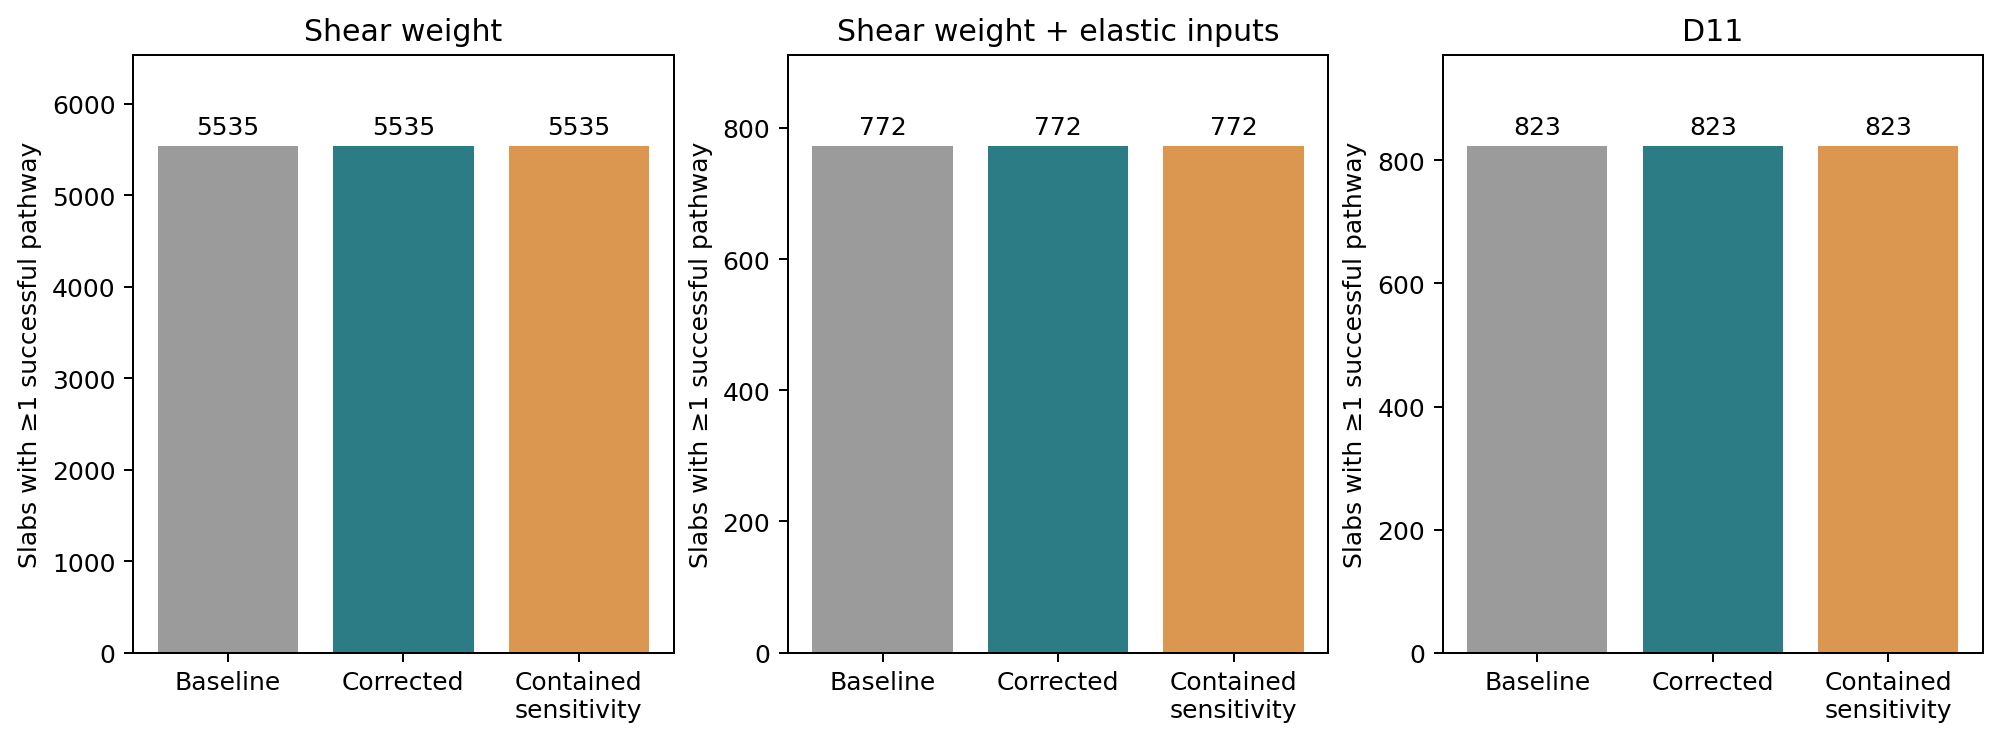

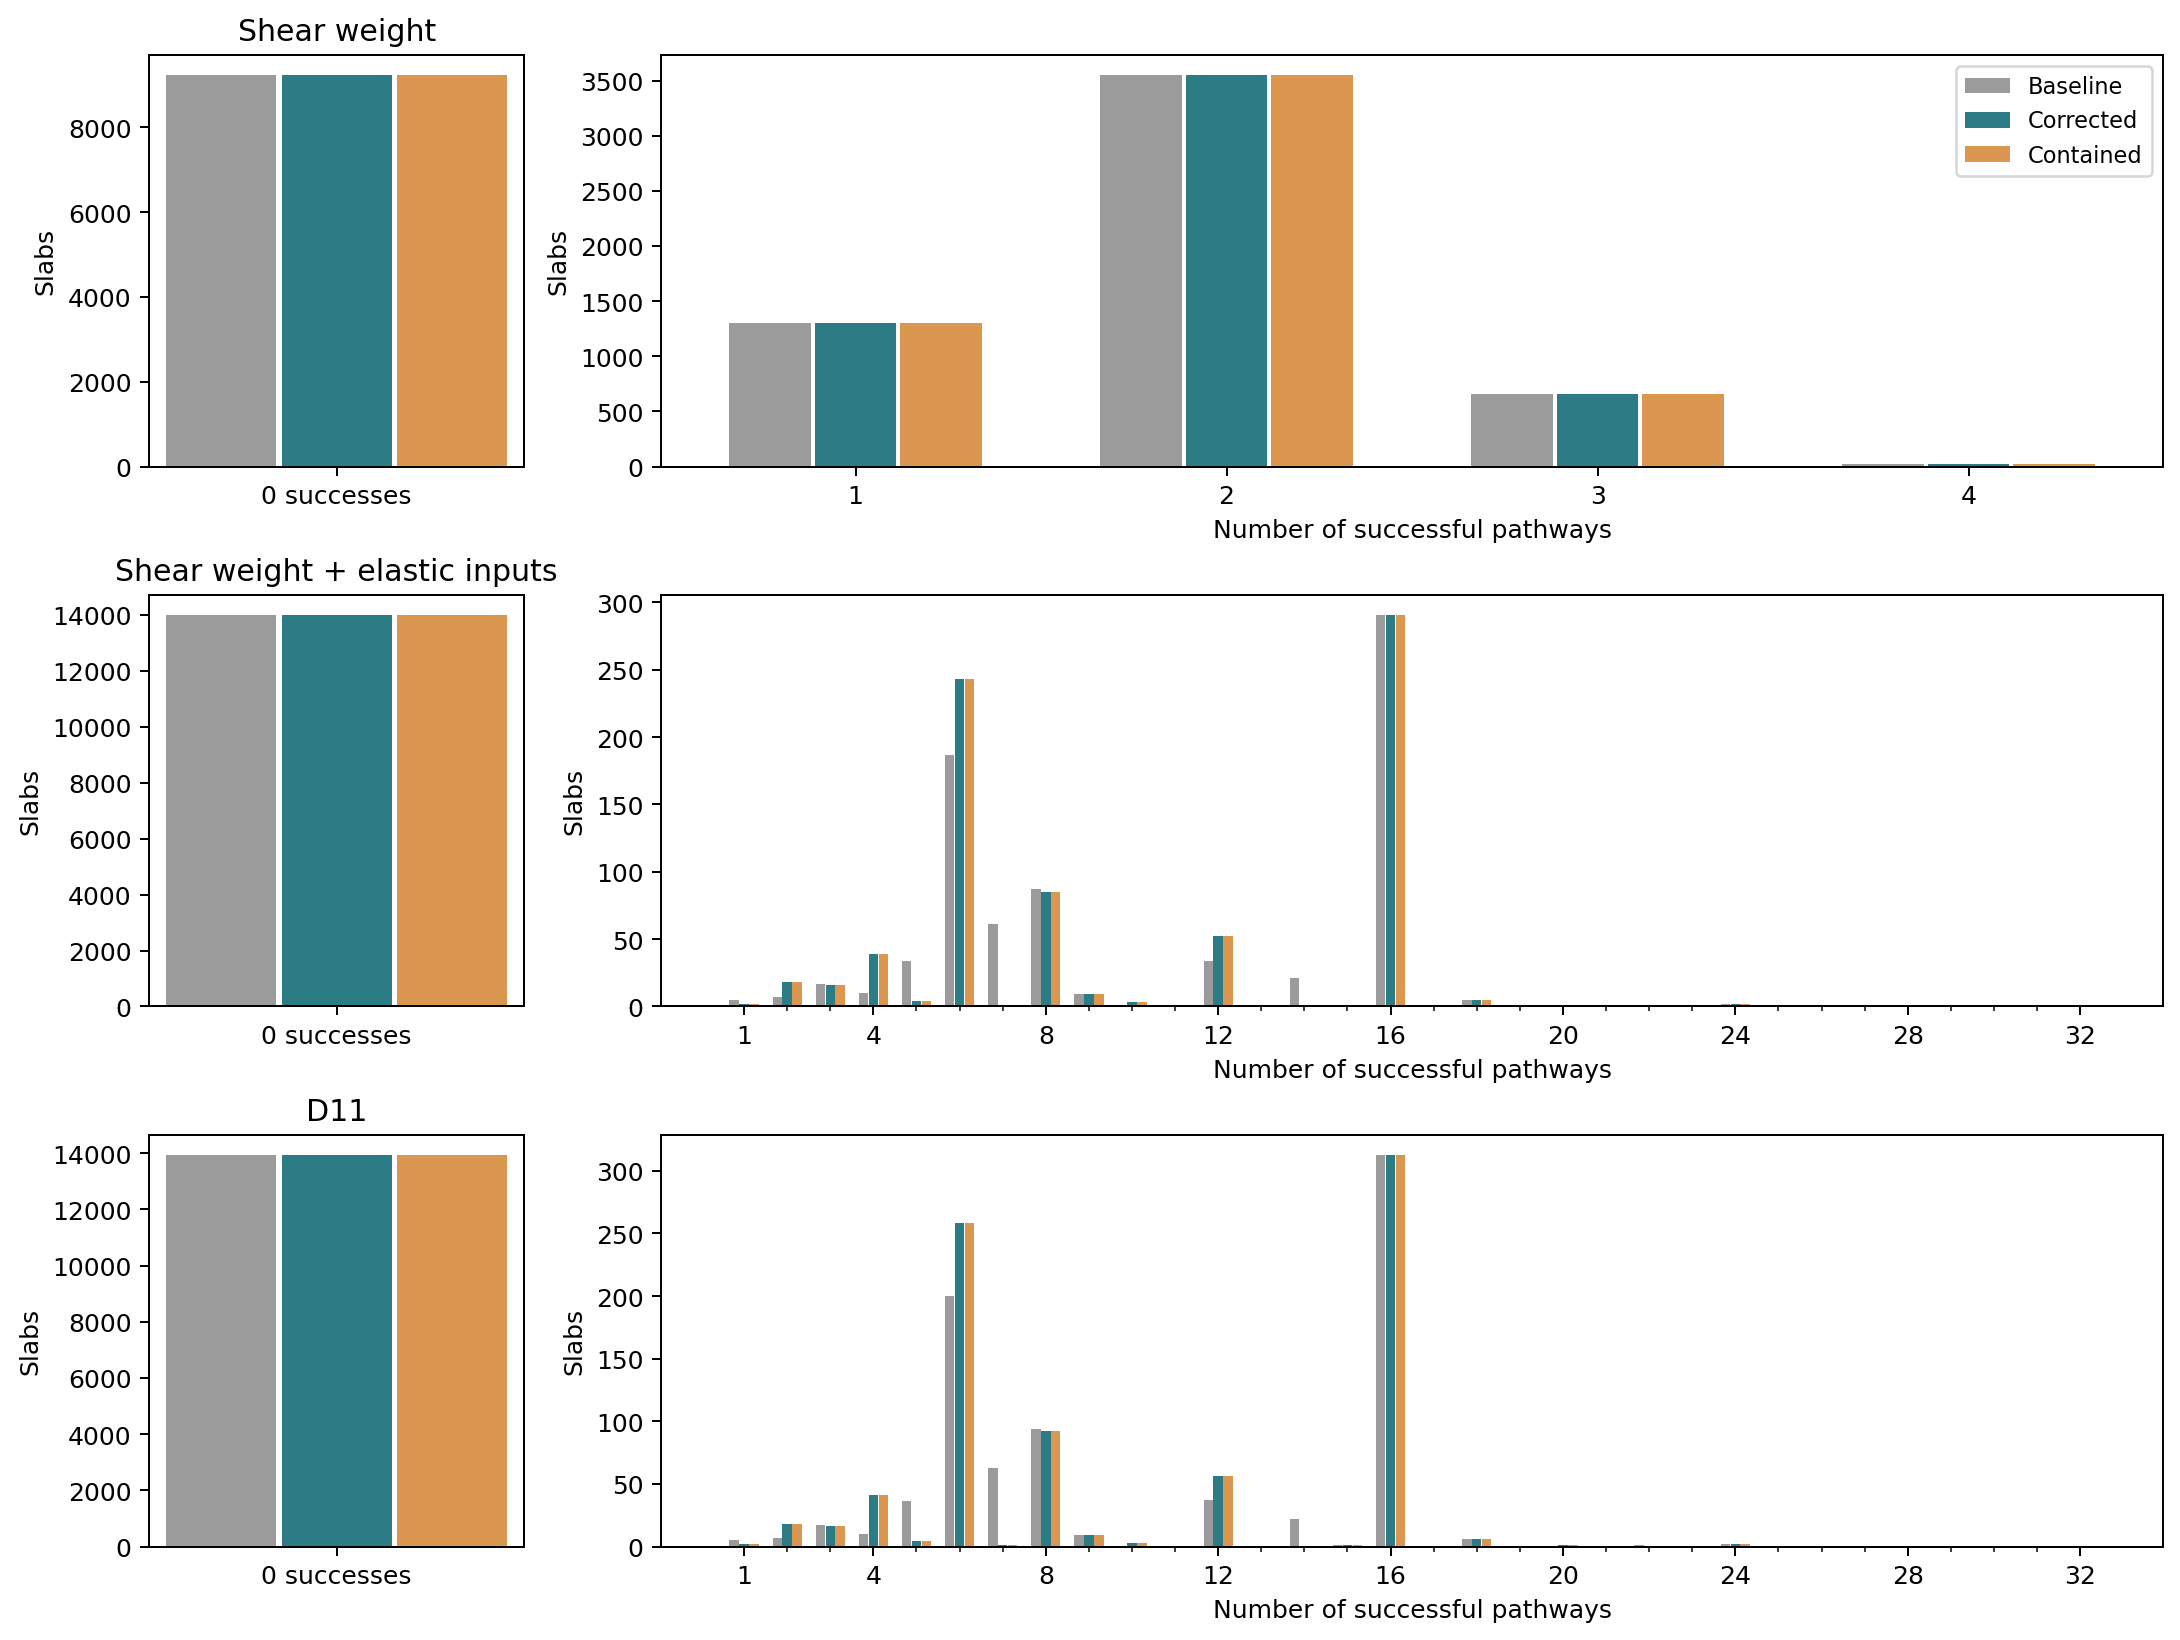

In [3]:
display(pd.Series(audit).to_frame("audit"))
display(Image(filename=str(results / "figures/union_coverage.png")))
display(Image(filename=str(results / "figures/successful_pathway_distributions.png")))

## D11 comparison

Pooled uncertainty counts slab–pathway pairs; per-slab summaries have their own aggregation. Interval separation is descriptive. Negative lower endpoints remain unclipped. See `../examples/D11_analysis.ipynb` for the illustrations and per-slab statistics.

{'additional_tests_from_contributing_pits': 33,
 'common_pits': 283,
 'common_slabs': 316,
 'grain_forms': ['RG'],
 'illustrations': [{'quantile': 0.3,
   'slab_id': '1057_slab_0',
   'spread_ratio': 31.778037197602032},
  {'quantile': 0.6,
   'slab_id': '50003_slab_0',
   'spread_ratio': 35.90580420862919},
  {'quantile': 0.9,
   'slab_id': '14909_slab_0',
   'spread_ratio': 62.966210819656524}],
 'layer_count_distribution': {'1': 257, '2': 41, '3': 17, '5': 1},
 'layer_occurrences': 395,
 'median_relative_uncertainty': {'max': 0.8977186929558909,
  'median': 0.7583034117516496,
  'min': 0.48174432473647577,
  'n': 316,
  'q25': 0.7583034117516496,
  'q75': 0.7971615466891209,
  'q90': 0.8361902680914164},
 'members_added_vs_baseline': [],
 'members_removed_vs_baseline': [],
 'negative_lower_endpoints': 1044,
 'nonoverlap_fraction': {'max': 0.6666666666666666,
  'median': 0.5,
  'min': 0.26666666666666666,
  'n': 316,
  'q25': 0.4,
  'q75': 0.5,
  'q90': 0.5666666666666667},
 'pathway

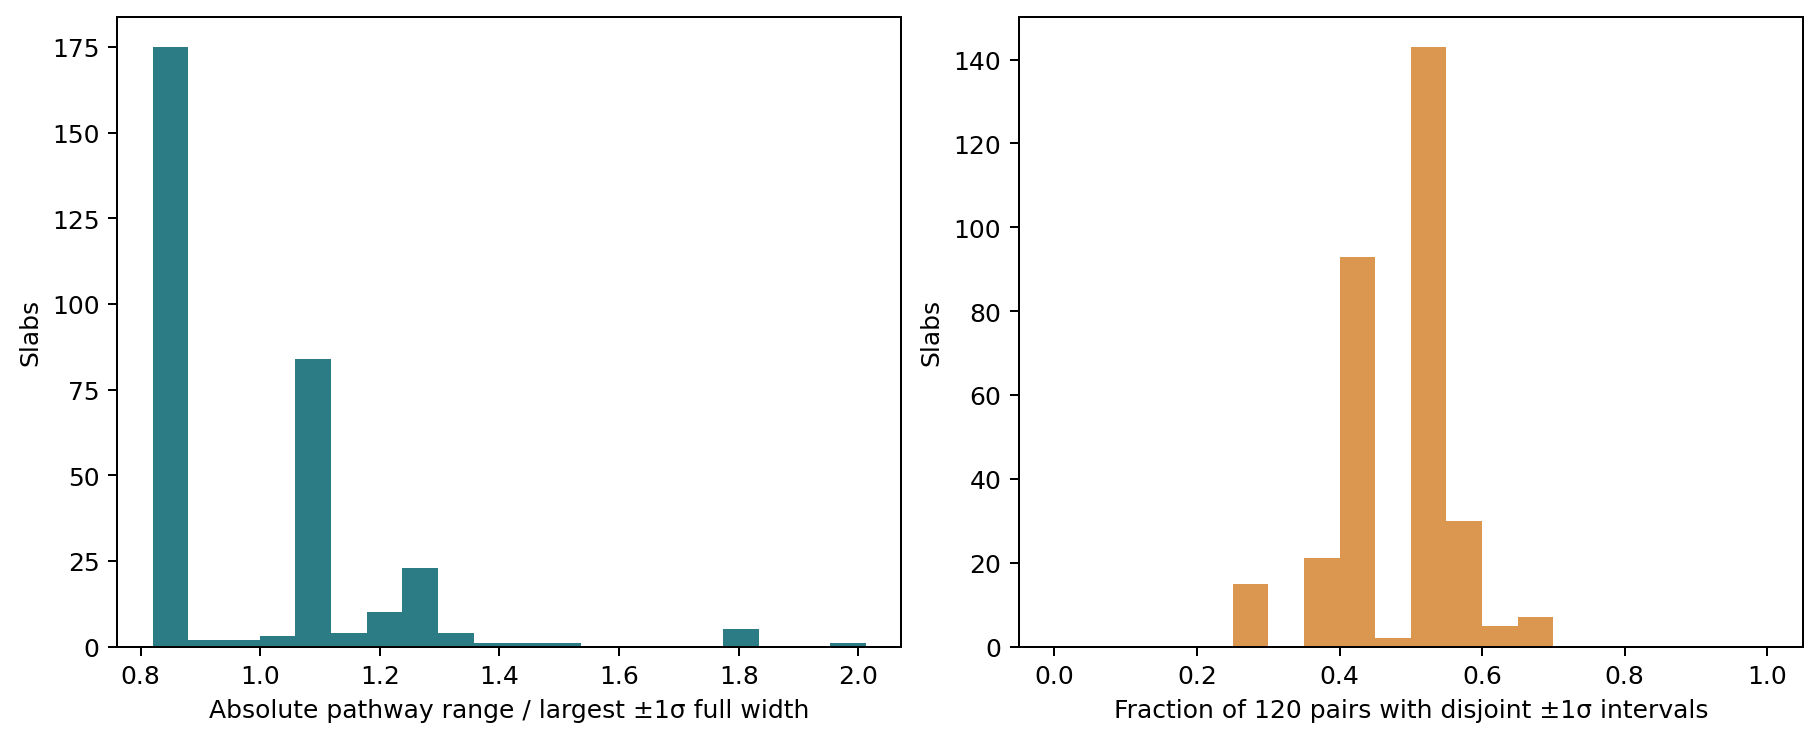

In [4]:
display(comparison["D11"]["corrected"])
display(Image(filename=str(results / "figures/d11_spread_uncertainty.png")))

## Monte Carlo and correlation sensitivity

Every condition uses 20,000 Gaussian raw-input draws with the recorded seed. Correlations 0, 0.5 and 1 apply separately within each measurement type across layers. Pathways share input draws. Failure counts plus successes equal all draws; successful-draw statistics are conditional where failures occur. These hypothetical scenarios do not estimate a population covariance model.

In [5]:
mc = pd.read_csv(results / "corrected/monte_carlo.csv")
counts = ["physical_input_failure", "method_domain_failure", "numerical_failure", "success"]
assert mc[counts].sum(axis=1).eq(mc.draws).all()
assert mc.draws.eq(20000).all()
cols = ["case", "pathway", "correlation", "first_order_nominal", "first_order_sigma", "conditional_mean", "conditional_median", "conditional_std", "conditional_p16", "conditional_p84", "success_fraction"]
display(mc.loc[~mc["case"].str.contains("_slab_"), cols])
display(mc.loc[mc["case"].str.contains("_slab_"), cols])

                     case                          pathway  correlation  \
0          linear_density                       geldsetzer          0.0   
1          linear_density                       geldsetzer          0.5   
2          linear_density                       geldsetzer          1.0   
3       nonlinear_density                       geldsetzer          0.0   
4       nonlinear_density              kim_jamieson_table2          0.0   
5       nonlinear_density                       geldsetzer          0.5   
6       nonlinear_density              kim_jamieson_table2          0.5   
7       nonlinear_density                       geldsetzer          1.0   
8       nonlinear_density              kim_jamieson_table2          1.0   
9       kim_t6_grain_size              kim_jamieson_table6          0.0   
10      kim_t6_grain_size              kim_jamieson_table6          0.5   
11      kim_t6_grain_size              kim_jamieson_table6          1.0   
12        homogeneous_D11

             case                                         pathway  \
48    1057_slab_0                geldsetzer -> bergfeld -> kochle   
49    1057_slab_0            geldsetzer -> bergfeld -> srivastava   
50    1057_slab_0                  geldsetzer -> kochle -> kochle   
51    1057_slab_0              geldsetzer -> kochle -> srivastava   
52    1057_slab_0               geldsetzer -> schottner -> kochle   
..            ...                                             ...   
241  50003_slab_0     kim_jamieson_table2 -> kochle -> srivastava   
242  50003_slab_0      kim_jamieson_table2 -> schottner -> kochle   
243  50003_slab_0  kim_jamieson_table2 -> schottner -> srivastava   
244  50003_slab_0        kim_jamieson_table2 -> wautier -> kochle   
245  50003_slab_0    kim_jamieson_table2 -> wautier -> srivastava   

     correlation  first_order_nominal  first_order_sigma  conditional_mean  \
48           0.0         7.286510e+07       7.453437e+07      8.094586e+07   
49           0.

## Runtime and reproducibility

Stages run sequentially. The OS file cache is warm and uncontrolled; each timing repeat uses a fresh engine. Timing establishes performance on the recorded hardware, not operational suitability. Source hashes and the compressed input manifest identify the exact inputs.

In [6]:
display(metadata["hardware"])
display(pd.Series(metadata["step_seconds"]).to_frame("seconds"))
display(pd.DataFrame(json.loads((results / "corrected/benchmarks.json").read_text())["runs"]))

{'chip_type': 'Apple M5',
 'logical_cpus': 10,
 'machine': 'arm64',
 'machine_model': 'Mac17,2',
 'machine_name': 'MacBook Pro',
 'number_processors': 'proc 10:4:6:0',
 'physical_memory': '16 GB',
 'platform': 'macOS-26.6.2-arm64-arm-64bit-Mach-O'}

                                                       seconds
review_compute.py --data /Users/marykate/Deskto...  104.372234
review_compute.py --data /Users/marykate/Deskto...  114.798743
review_compute.py --data /Users/marykate/Deskto...  137.692019
review_diagnostics.py --data /Users/marykate/De...  138.230874
review_diagnostics.py --data /Users/marykate/De...  134.672250
review_diagnostics.py --data /Users/marykate/De...  134.685664
review_monte_carlo.py --data /Users/marykate/De...    0.984753
review_report.py --results /Users/marykate/Desk...    4.990367

   repeat   seconds  slabs
0       1  0.583945    100
1       2  0.560410    100
2       3  0.566154    100
3       1  6.866386   1000
4       2  6.657153   1000
5       3  6.251811   1000